<a href="https://colab.research.google.com/github/efyja15/ML4Eng/blob/main/mmme4125_coursework_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MMME4125 2026/2027 Coursework**

**Student Name:** [Enter your full name here]

**Student ID:** [Enter your student ID here]

# **Project Description**

In this coursework, you will analise historical data and build your own machine learning pipeline demonstrating your knowledge on data exploration, data preparation and machine learning model development to solve a prediction or classification task  of an engineering domain problem.

**Dataset:** You will select a data set from a range of data sets provided in this module's Moodle page.

**Overall task:** Utilising your selected data set, you will build at least two models of your choice either for regression or classification (depending on the data set you selected) from the ones covered during lectures (e.g. NN, Decision Trees, Randon Forest, CNN to name a few examples). Employ appropriate methods from the pandas, matplotlib, keras and sklearn libraries to analyse and process the dataset and for building predictive models.

**Note:** You must use only pandas, numpy, matplotlib, keras and sklearn or any other specific library that was covered during class for example for data augmentation. Do not use other libraries or external packages. Use of such packages may receive zero credit for the affected parts.

**Format:** Use this Jupyter Notebook as a template to write your report/answers to questions in Markdown cells, supported by your source code in Code cells.

The project (and this notebook) are structured in three main tasks:

**(Task 1)** -  Data set selection & data exploration : Once you select the data set you will carry out an initial Exploratory Data Analysis (EDA). Some data sets might be too large, containing multiple features or measurements of multiple variables. As you explore your data, you will make a decision of which sub set of your data you will use for your prediction/classification task. **You will then discuss this decision with your lab tutor (you will book a slot for this during lab hours) and get feedback**. As it will be indicated later in this notebook, you will add as markdown your analysis of the EDA results, the feedback provided by the tutor and how this has been taken into account to move to the next task.

**(Task 2)** - Data preparation : with your chosen dataset (or subset), you will carry out the data preparation. This will include data visualisation (e.g. patterns, class imbalance, outliers), dealing with any missing values, outlier handling, scaling/normalisation, feature extraction, data reduction/augmentation, creating of training,validaton and test sets).

**(Task 3)** - Model Development & Metrics Analysis : once your data set is ready, select two ML approaches from the ones covered during the lectures and discuss your selection with your lab tutor (**you will need to book a second lab slot for this and get feedback**). You will add in a Markdown cell your rationale for chosing such models, providing details of the feedback provided by the lab tutor and how it was used to move forward. Additional rationale for the specific hyper-parameters should also be included. Implementation should be added in a Code cell with appropriate code comments. Appropriate metrics for the model used should be implemented and presented (e.g. RMSE, Precision, Recall, F-Score, confusion matrix). You may want to try multiple hyper parameters to understand how the model behaves and if further iprovement can be obtained. In a Markdown cell, please explain the results obtained on both models and present a discussion of results. This discussion should include your insights on how model design/hyper-parameters affected the quality of the results.


Ensure your code produces the corresponding plots or results addressing the questions. Rename this .ipynb file to 202627_MMME4125_cw_XXX.ipynb, where XXX is your username (e.g., psxyz), and submit it to Moodle by **DATE**

**Marks**: The coursework is worth a total of 100 marks (accounting for 70% of the module grade). Marks will be awarded based on your understanding of machine learning theories, the informativeness and presentation of your code, visualisations, results (e.g., code comments, necessary labels in plots) and analysis, evidence of feedback and how it was addressed, your self-learning ability in solving the specific problem, and how succinct and clear your report writing is.

In [32]:
# You can change the import statements as you wish, but you should not use any library beyond pandas, numpy, matplotlib, and sklearn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

<div class="alert alert-success" style="text-align:left;">
<h2>Task 1. Dataset Selection & Exploratory Data Analysis<span style="float:right;">[25 marks]</span></h2></div>

### Task 1a. <span style="color:red">(10 marks)</span>

Start by introducing the engineering problem that you will be addressing, what the current industrial practice is to solve this problem and why ML is a good approach to solve it (3 marks). Explain the data set you have selected by providing details on what each variable represents, if you suspect there are any likely measurement problems, if there are any variables that could introduce leakage and if any mechanical principles may provide initial plausible relationships across these variables (5 marks).  Finally explain why this is a regression or a classification task (2 marks).

The current practice for aerospace assembly is completed majoritively by hand which leads to cost and quality problems. With this, it would be benificial to move to automation in these processes. using ML for drilling means that we can train it to spot anomilies with a good level of accuracy.
this is a classification task as it is identifying errors in the drilling processes.

### Task 1b. <span style="color:red">(5 marks)</span>

Select a subset of the data to be visualised. Include a rationale for inspecting this particular subset of data (2 mark). Produce at least 3 plots (1 mark each) to visualise patterns, distribution, class imbalance, outliers and correlations. The types of plots you use will  be determined by the type of data you are handling. These plots should be informative of the next steps you will carry out during data preparation.

In [33]:
#Looking at the data
#import pandas as pd
#df = pd.read_csv('_1 0mmThuFeb081347562024.csv', sep=',')
# this code could not seperate the columbs and thus couldn't do anthing with the
# data, lookded online for help

import pandas as pd

df = pd.read_csv('_1 0mmThuFeb081347562024.csv',
    skiprows=2,
    header=0)

print(df.head())


   Index      Time               INORM                IEFF               POSF  \
0    NaN      msec                A(p)                A(p)                 mm   
1    0.0  0.000000  -1.000000000000000  -9.215746109246261  0.000000000000000   
2    1.0  1.000000   1.000000000000000  -9.139456820262435  0.000000000000000   
3    2.0  2.000000   3.000000000000000  -9.139456820262435  0.000000000000000   
4    3.0  3.000000   1.000000000000000  -9.139456820262435  0.000000000000000   

        PSDATA:INORM  
0               A(p)  
1  0.250000000000000  
2  0.125000000000000  
3  0.125000000000000  
4  0.250000000000000  


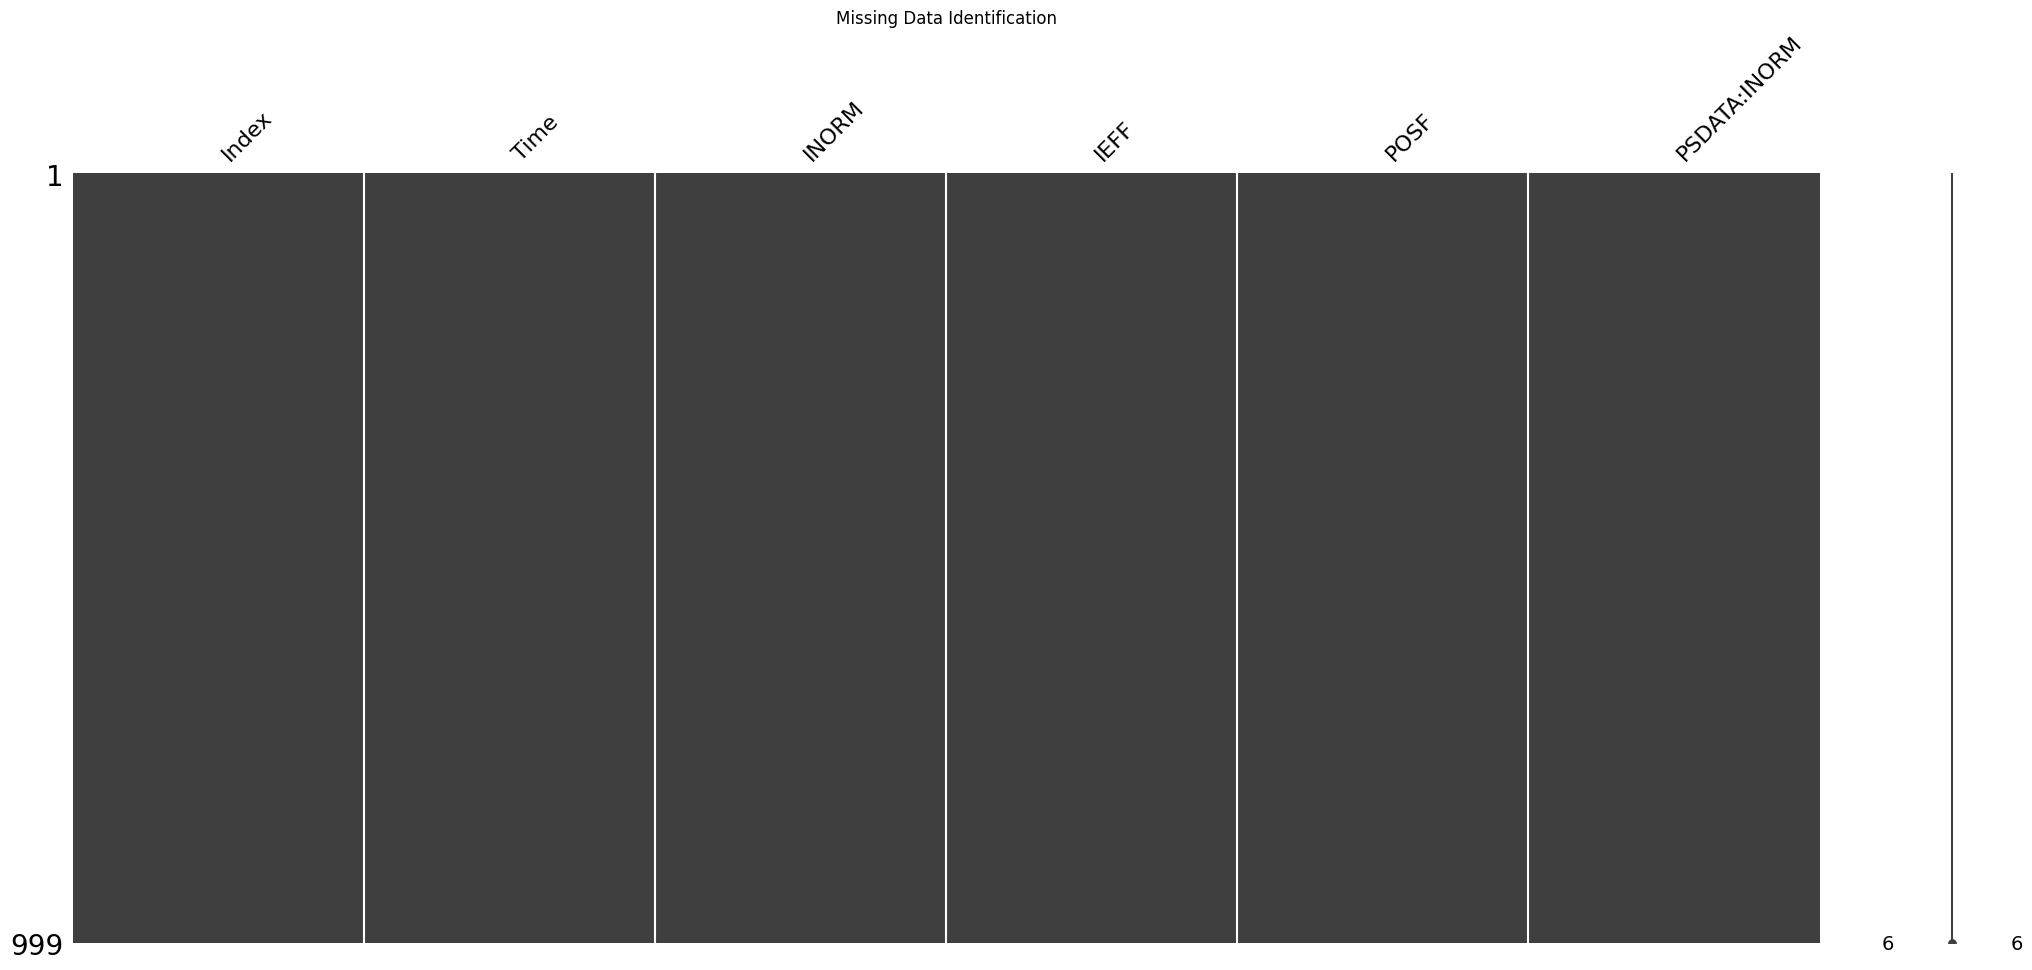

In [34]:
# Task 1b. Insert your code here for plot 1
# Look for missing data values using a missingno matrix
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

subset = df.iloc[1:1000] #Reduce the amount of data
msno.matrix(subset)
plt.title("Missing Data Identification")
plt.show()

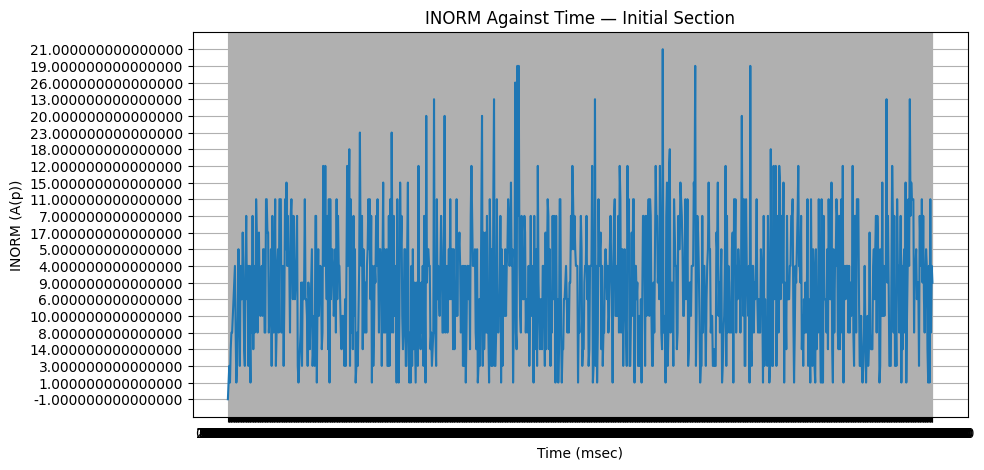

In [35]:
# Insert your code here for plot 2
# Line graph to show the trend of data


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(subset['Time'], subset['INORM'])
plt.xlabel('Time (msec)')
plt.ylabel('INORM (A(p))')
plt.title('INORM Against Time — Initial Section')
plt.grid(True)
plt.show()

In [36]:
type(subset[['INORM']]) #trying to find errors in INORM
subset[['IEFF']].info()
subset['IEFF'].head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 1 to 999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   IEFF    999 non-null    object
dtypes: object(1)
memory usage: 7.9+ KB


,IEFF
1,-9.215746109246261
2,-9.139456820262435
3,-9.139456820262435
4,-9.139456820262435
5,-9.139456820262435
6,-9.139456820262435
7,-9.139456820262435
8,-9.139456820262435
9,-9.139456820262435
10,-9.200488251449496


/tmp/ipykernel_6317/2589915509.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset['IEFF'] = pd.to_numeric(subset['IEFF'], errors='coerce')


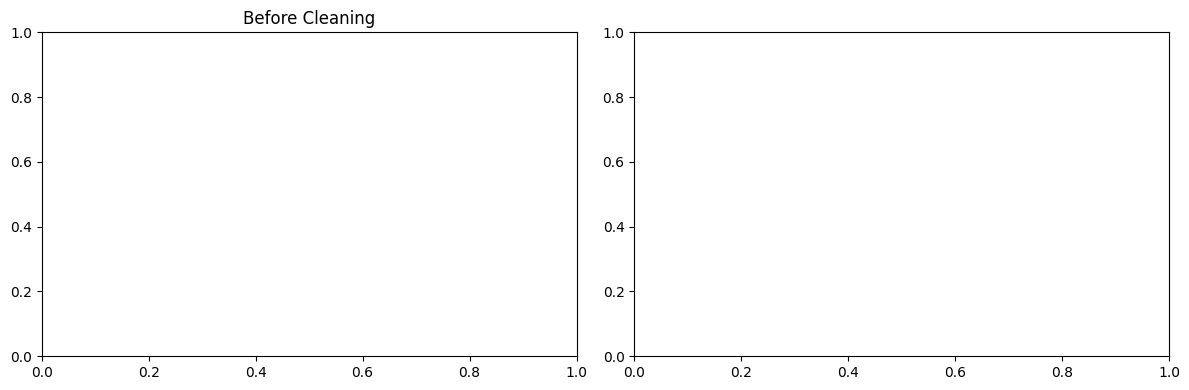

In [37]:
# Insert your code here for plot 3
#Box plot to look for outlier data
import matplotlib.pyplot as plt

subset['IEFF'] = pd.to_numeric(subset['IEFF'], errors='coerce')
subset['IEFF'].dtype
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
#axes[0].boxplot(subset['INORM'], errors='coerce')
axes[0].set_title("Before Cleaning")




plt.tight_layout()
plt.show()

In [38]:
# you may include more plots that may be helpful for analysis



### Task 1c. <span style="color:red">(10 marks)</span>

-By using your plots from 1b, provide an analysis of the data (e.g. observed patterns, correlations, potential best predictors) and briefly explain how each code snippet supports your evaluation of potential issues with the data (5 marks).

-Once you have done your analysis/insights you should discuss this with your lab tutor (you need to book a slot in lab hours for this), capture that feedback, report it here as well as a reflection of how the feedback informs the next steps of data processing (5 marks).

From thes plots we can determine that there are no missing values within the 1000 data point range.

<div class="alert alert-success" style="text-align:left;">
<h2>Task 2. Data Preparation<span style="float:right;">[40 marks]</span></h2></div>

### <span style="color:red">IMPORTANT NOTE: </span>
This the beginning of your ML building pipeline. All transformations that happen to the data from here onwards may be stateless or stateful. Make a concious decision at which step of the entire process you need to split your data set into training, validation and test set. **Add an additional Code cell** for data splitting when you think it is reasonable to do so as well as **add a Markdown cell** to explain why the data set is splitted at this point of the ML pipeline and the impact data transformation operations might have on the validity of the model if the splitting is not carried out beforehand. You should also justify your train-validation-test splitting stategy.
### <span style="color:red">(8 marks) </span>

### Task 2a. Data Cleaning <span style="color:red">(7 marks)</span>
Using the libraries specificied at the top of the notebook or any other one covered in class, start cleaning your data by handling missing values, handling any duplicates and deal with outliers. Justify your methods.

*Task 2a. Add your justification here*

In [39]:
# Task 2a. Add your code here

### Task 2b. Data Transformation <span style="color:red">(5 marks)</span>
Perform any necessary normalisation and encoding of categorical variables. Please explain why this step is necessary when building a predictive model and justify the method used.

In [40]:
# Task 2b. Add your code here

*Task 2b. Add your explanation here*

### Task 2c. Data Reduction/Augmentation  <span style="color:red">(10 marks)</span>

Based on your data set implement either data reduction or data augmentation depending on the needs of the problem and data (5 marks). Explain why data reduction or data augmentation is necessary in the context of your engineering problem and the data set you selected as well as justify the methods used (5 marks). One thing to note is that depending on your data set, data reduction might have to be done after Task 2d Feature Engineering, so make sure you apply these two steps (Task 2c and Task 2d) in the correct order according to your data.

**Note**: If you do have to do 2d before 2c, then just make sure your code is in the correct order in the code cells below.

In [41]:
# Task 2c. Add your code here

*Task 2c. Add your explanation and justification here*

### Task 2d. Feature Engineering   <span style="color:red">(10 marks)</span>

An important aspect of machine learning is understanding the feature space and shaping it before training. That is, preprocessing or reshaping the data in a way that provides more relevant information and an easier job for the regressor or classifier.

Perform any feature engineering that you might think it is ideal for the type of task you are aiming (4 marks). This could include statistical features, rolling window statistics,  frequency analysis (FFT) or any others covered in lectures.

If either you are going to work directly with the raw data, or you will be engineering features, justify why this is the case in the context of the engineering problem you are trying to solve, justifying any specific features used (3 marks). In the case of raw data, perform any additional transformation that would be needed to work with this raw data directly.

Assess whether all data is ready for model building. If not, complete the preparation of a model-ready dataframe from your cleaned dataset. More specifically, make sure to assess whether all predictors in your prepared dataframe are directly suitable for the machine learning task, state why this is the case  and state what(if anything) still needs processing, and process / make the necessary adjustment in the data accordingly (3 marks).

In [42]:
# Task 2c. Add your code here

Task 2c. Add your explanations/justifications here

<div class="alert alert-success" style="text-align:left;">
<h2>Task 3. ML Model Building<span style="float:right;">[35 marks]</span></h2></div>

### Task 3a. Building a base  model <span style="color:red">(10 marks)</span>

Now, after meeting your tutor for the second time to discuss your preliminary model selection and reasons for such method (you need to book again a slot during your lab for this) select and build a baseline model from scratch (e.g. define architecture in the case of NN) to predict or classify according to your problem using the preprocessed dataset.

- Train the model and report **three different** evaluation metrics (3 marks).
- Reflecting from  your tutor feedback, explain how this feedback influenced the ML model selected, why is it appropriate for the task? why the hyper-parameters used? (4 marks)
- For each metric, explain (in a single short sentence) why it is relevant and whether the observed value suggests sensible predictions/classifications, i.e. what the values within the metric mean (3 marks).

In [43]:
#Add your code here

Add your justification for metrics here and what the results obtained mean.

### Task 3b. Hyper-parameter exploration <span style="color:red">(10 marks)</span>

You have now build a base model, with some initial results. It is now your task to experiment with hyper-parameters (5 marks) to see if you can improve the quality of your results. It is up to you how you approach this process, but you need to justify (5 marks ) the approach you are taking and discuss the results. What effect is having the changes you are doing to the approach?

In [44]:
#perform your different hyper-parameter optimisation/changes here

Add here your justification for how you are approaching the hyper-parameter tuning  and discuss your results.

### Task 3c. Additional Models and Final Analysis <span style="color:red">(15 marks)</span>

Implement at least one more method of your choice.Report model quality with clear evidence (metrics). Compare with the baseline using supportive tables or visualisations (4 marks), and discuss the strengths and limitations of each (3 marks). Finally, provide a discussion (8 marks) on:

Why this type of model and would you deploy it in a real environment? why?

Under what operating conditions would you not trust it? how could you improve it?

What additional sensor would you collect and why?

Are the important features physically plausible?

In [45]:
# your implementaiton of additional methods here together with metrics

Add here your discussion on strengths and limitations of each method